# WEEK 2 - DAY 4
## TASK 1: METRICS ON IMBALANCED DATA

In [1]:
# 1: Import required libraries

import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 2: Create an imbalanced dataset

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=5,
    n_redundant=2,
    n_classes=2,
    weights=[0.95, 0.05],
    flip_y=0,
    random_state=42
)

print("Class Distribution:")
print("Majority class (0):", np.sum(y == 0))
print("Minority class (1):", np.sum(y == 1))

# 3: Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4: Train a Majority Class Model

majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)

y_pred_majority = majority_model.predict(X_test)

print("\nMajority Class Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_majority))
print("Precision:", precision_score(y_test, y_pred_majority, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_majority, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_majority, zero_division=0))

# 5: Train Logistic Regression

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("\nLogistic Regression - Classification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

# 6: Train Logistic Regression with Balanced Class Weight

balanced_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

balanced_model.fit(X_train, y_train)

y_pred_balanced = balanced_model.predict(X_test)

print("\nLogistic Regression with class_weight='balanced':")
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_balanced, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_balanced, zero_division=0))

# 7: Compare Recall and F1 Score

print("\nComparison of Logistic Regression Models:")
print(f"{'Metric':<12}{'Normal Model':<18}{'Balanced Model'}")

print(f"{'Recall':<12}{recall_score(y_test, y_pred_lr):<18.4f}{recall_score(y_test, y_pred_balanced):.4f}")

print(f"{'F1 Score':<12}{f1_score(y_test, y_pred_lr):<18.4f}{f1_score(y_test, y_pred_balanced):.4f}")

Class Distribution:
Majority class (0): 950
Minority class (1): 50

Majority Class Model:
Accuracy: 0.95
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Logistic Regression - Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       190
           1       0.75      0.30      0.43        10

    accuracy                           0.96       200
   macro avg       0.86      0.65      0.70       200
weighted avg       0.95      0.96      0.95       200

Confusion Matrix:
[[189   1]
 [  7   3]]

Logistic Regression with class_weight='balanced':
Accuracy: 0.82
Precision: 0.15789473684210525
Recall: 0.6
F1 Score: 0.25

Comparison of Logistic Regression Models:
Metric      Normal Model      Balanced Model
Recall      0.3000            0.6000
F1 Score    0.4286            0.2500


TP, FP, FN and TN – Fraud Detection Example

Imagine a bank detecting fraudulent transactions.

- True Positive (TP): A fraudulent transaction is correctly identified as fraud.
- True Negative (TN): A genuine transaction is correctly identified as genuine.
- False Positive (FP): A genuine transaction is incorrectly identified as fraud.
- False Negative (FN): A fraudulent transaction is incorrectly identified as genuine.

For our Logistic Regression confusion matrix:

"[[189, 1], [7, 3]]"

- TN = 189
- FP = 1
- FN = 7
- TP = 3

## TASK 2: ROC CURVE AND AUC

In [2]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


Logistic Regression AUC: 0.7747
Random Forest AUC: 0.9774
XGBoost AUC: 0.9458


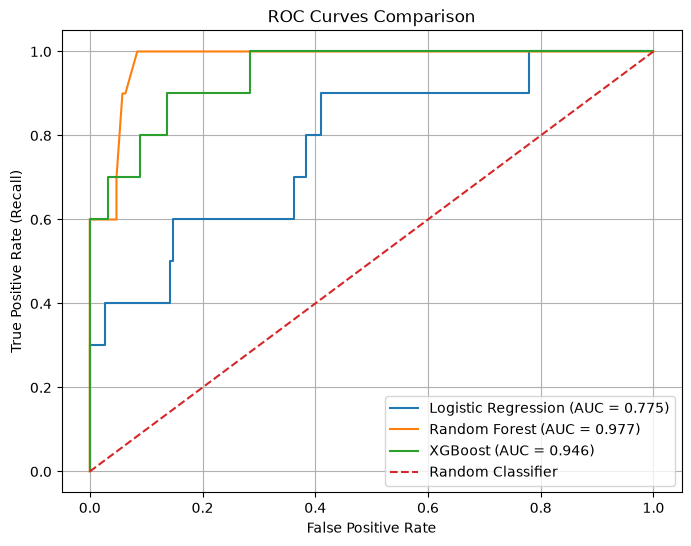


Threshold Results (Minimum Recall = 80%):
              Model  Threshold  Precision  Recall
Logistic Regression     0.0222     0.1034     0.9
      Random Forest     0.0700     0.4500     0.9
            XGBoost     0.0203     0.3200     0.8


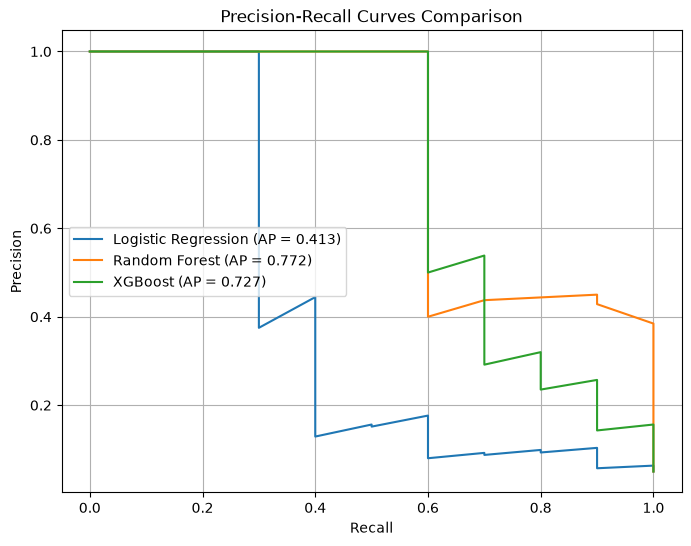


Model Comparison:
              Model    AUC     F1
Logistic Regression 0.7747 0.4286
      Random Forest 0.9774 0.5714
            XGBoost 0.9458 0.6667


In [4]:
# 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# 2: Create an imbalanced dataset

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=5,
    n_redundant=2,
    n_classes=2,
    weights=[0.95, 0.05],
    flip_y=0,
    random_state=42
)

# 3: Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4: Create three classification models

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42
    )
}

# 5: Train models and get prediction probabilities

probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_proba = model.predict_proba(X_test)[:, 1]

    probabilities[name] = y_proba

    print(name, "AUC:", round(roc_auc_score(y_test, y_proba), 4))

# 6: Plot all three ROC curves in one chart

plt.figure(figsize=(8, 6))

for name, y_proba in probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves Comparison")
plt.legend()
plt.grid()
plt.show()

# 7: Find threshold with at least 80% recall

threshold_results = []

for name, y_proba in probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test, y_proba
    )

    # Ignore the last precision and recall values
    valid_indices = np.where(recall[:-1] >= 0.80)[0]

    if len(valid_indices) > 0:

        # Select the threshold with the highest precision
        best_index = valid_indices[
            np.argmax(precision[:-1][valid_indices])
        ]

        best_threshold = thresholds[best_index]
        best_precision = precision[best_index]
        best_recall = recall[best_index]

        threshold_results.append({
            "Model": name,
            "Threshold": best_threshold,
            "Precision": best_precision,
            "Recall": best_recall
        })

    else:
        threshold_results.append({
            "Model": name,
            "Threshold": np.nan,
            "Precision": np.nan,
            "Recall": np.nan
        })

print("\nThreshold Results (Minimum Recall = 80%):")
print(pd.DataFrame(threshold_results).round(4).to_string(index=False))

# 8: Plot Precision-Recall curves

plt.figure(figsize=(8, 6))

for name, y_proba in probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test, y_proba
    )

    ap = average_precision_score(y_test, y_proba)

    plt.plot(
        recall, precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves Comparison")
plt.legend()
plt.grid()
plt.show()

# 9: Create Model Comparison Table

comparison = []

for name, y_proba in probabilities.items():

    y_pred = (y_proba >= 0.5).astype(int)

    comparison.append({
        "Model": name,
        "AUC": roc_auc_score(y_test, y_proba),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison)

print("\nModel Comparison:")
print(comparison_df.round(4).to_string(index=False))

When to Use F1 and AUC

1. F1-score is useful when we need a balance between precision and recall.
2. It is especially useful for imbalanced datasets.
3. AUC is useful when comparing how well models distinguish between classes across different thresholds.
4. F1 is useful for evaluating a selected threshold, while AUC evaluates overall ranking performance.

Conclusion

The Precision-Recall curve is generally more informative for imbalanced datasets because it focuses on the positive class and shows the trade-off between precision and recall. The ROC curve is also useful for evaluating the overall classification performance of a model.

## BONUS CHALLENGE: BEST THRESHOLD FUNCTION

In [5]:
# 1: Import required metric

from sklearn.metrics import precision_recall_curve

# 2: Define the best threshold function

def best_threshold(y_true, proba, min_recall):

    precision, recall, thresholds = precision_recall_curve(
        y_true, proba
    )

    # Find thresholds that satisfy minimum recall

    valid_indices = np.where(
        recall[:-1] >= min_recall
    )[0]

    # Check whether any valid threshold exists

    if len(valid_indices) == 0:
        return None

    # Select the threshold with highest precision

    best_index = valid_indices[
        np.argmax(precision[:-1][valid_indices])
    ]

    return thresholds[best_index]


# 3: Test the function using all three models

print("Best Threshold Results:")

for name, y_proba in probabilities.items():

    threshold = best_threshold(
        y_test,
        y_proba,
        min_recall=0.80
    )

    print(f"\n{name}:")

    if threshold is not None:

        y_pred = (y_proba >= threshold).astype(int)

        print("Best Threshold:", round(threshold, 4))
        print("Precision:", round(
            precision_score(y_test, y_pred, zero_division=0), 4
        ))
        print("Recall:", round(
            recall_score(y_test, y_pred, zero_division=0), 4
        ))

    else:
        print("No threshold satisfies the minimum recall.")

Best Threshold Results:

Logistic Regression:
Best Threshold: 0.0222
Precision: 0.1034
Recall: 0.9

Random Forest:
Best Threshold: 0.07
Precision: 0.45
Recall: 0.9

XGBoost:
Best Threshold: 0.0203
Precision: 0.32
Recall: 0.8


Conclusion

The best_threshold() function selects the threshold with the highest precision while maintaining the minimum required recall. It helps improve classification decisions for imbalanced datasets by balancing precision and recall according to the required condition.